<a href="https://colab.research.google.com/github/MiguelAP6/IAAC/blob/Pedro-Ferreira/Data_Understanding_PF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== 1. CARREGAMENTO DOS DADOS ===


Saving archive.zip to archive.zip

Dimensão do Dataset: 3000 linhas x 10 colunas

Primeiras 5 linhas:


,Country,Year,Attack Type,Target Industry,Financial Loss (in Million $),Number of Affected Users,Attack Source,Security Vulnerability Type,Defense Mechanism Used,Incident Resolution Time (in Hours)
0,China,2019,Phishing,Education,80.53,773169,Hacker Group,Unpatched Software,VPN,63
1,China,2019,Ransomware,Retail,62.19,295961,Hacker Group,Unpatched Software,Firewall,71
2,India,2017,Man-in-the-Middle,IT,38.65,605895,Hacker Group,Weak Passwords,VPN,20
3,UK,2024,Ransomware,Telecommunications,41.44,659320,Nation-state,Social Engineering,AI-based Detection,7
4,Germany,2018,Man-in-the-Middle,IT,74.41,810682,Insider,Social Engineering,VPN,68



Informação sobre Tipos de Dados e Nulos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Country                              3000 non-null   object 
 1   Year                                 3000 non-null   int64  
 2   Attack Type                          3000 non-null   object 
 3   Target Industry                      3000 non-null   object 
 4   Financial Loss (in Million $)        3000 non-null   float64
 5   Number of Affected Users             3000 non-null   int64  
 6   Attack Source                        3000 non-null   object 
 7   Security Vulnerability Type          3000 non-null   object 
 8   Defense Mechanism Used               3000 non-null   object 
 9   Incident Resolution Time (in Hours)  3000 non-null   int64  
dtypes: float64(1), int64(3), object(6)
memory usage: 234.5

,Coluna,Média,Mediana,Desvio Padrão,Mínimo,Máximo,Skewness (Assimetria),Kurtosis (Curtose)
0,Year,2019.570333,2020.000,2.857932,2015.0,2024.00,-0.027499,-1.229788
1,Financial Loss (in Million $),50.492970,50.795,28.791415,0.5,99.99,-0.016852,-1.210231
2,Number of Affected Users,504684.136333,504513.000,289944.084972,424.0,999635.00,-0.025384,-1.203698
3,Incident Resolution Time (in Hours),36.476000,37.000,20.570768,1.0,72.00,0.011098,-1.192629


/tmp/ipykernel_3294/1945813563.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=target_col, palette='viridis')


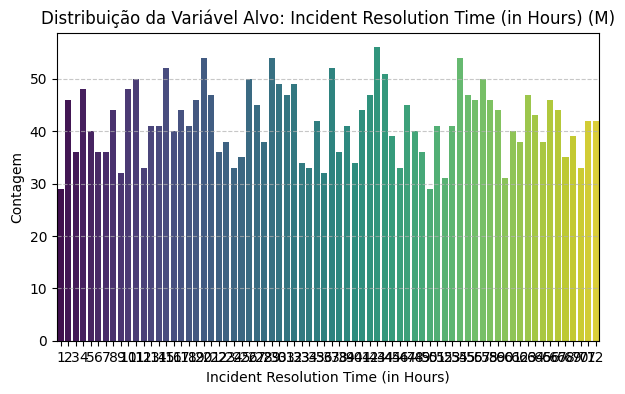

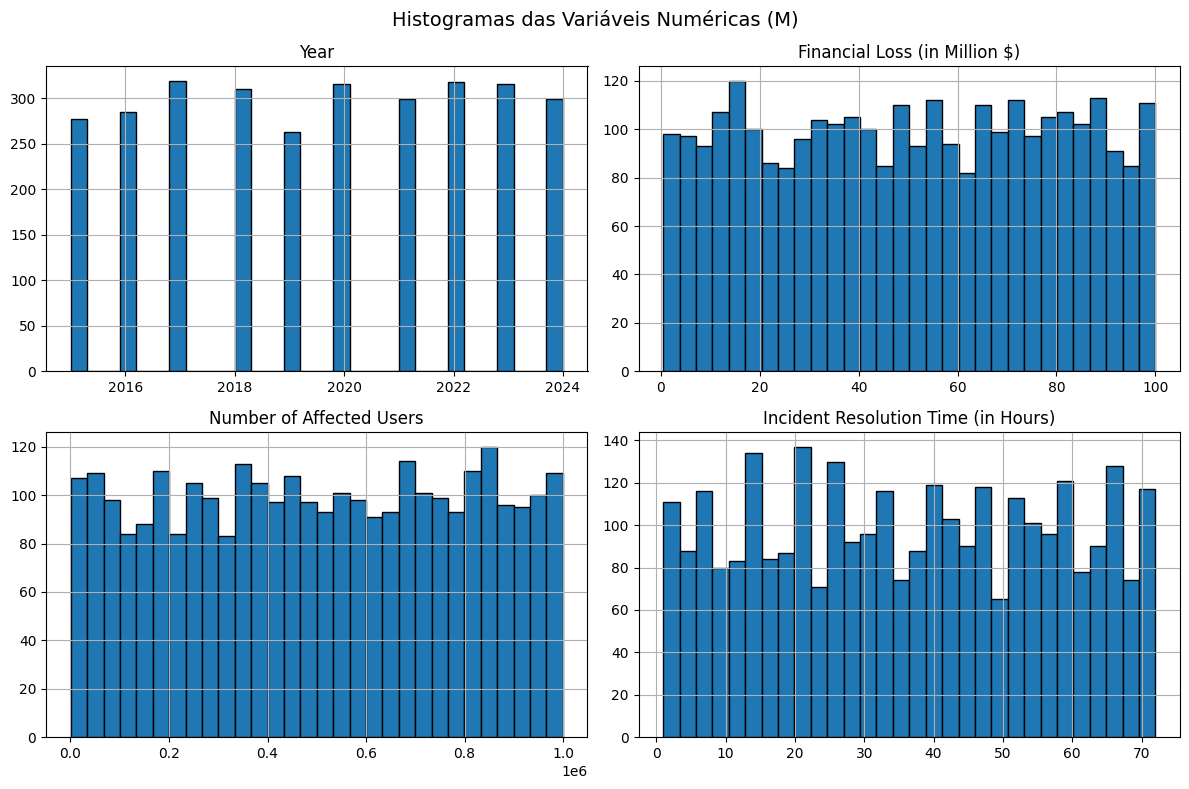


=== 3. ANÁLISE BIVARIADA & DETEÇÃO DE OUTLIERS (IQR - M) ===


/tmp/ipykernel_3294/1945813563.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, y=col, x=target_col, palette='Set2')
/tmp/ipykernel_3294/1945813563.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, y=col, x=target_col, palette='Set2')
/tmp/ipykernel_3294/1945813563.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, y=col, x=target_col, palette='Set2')
/tmp/ipykernel_3294/1945813563.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x`

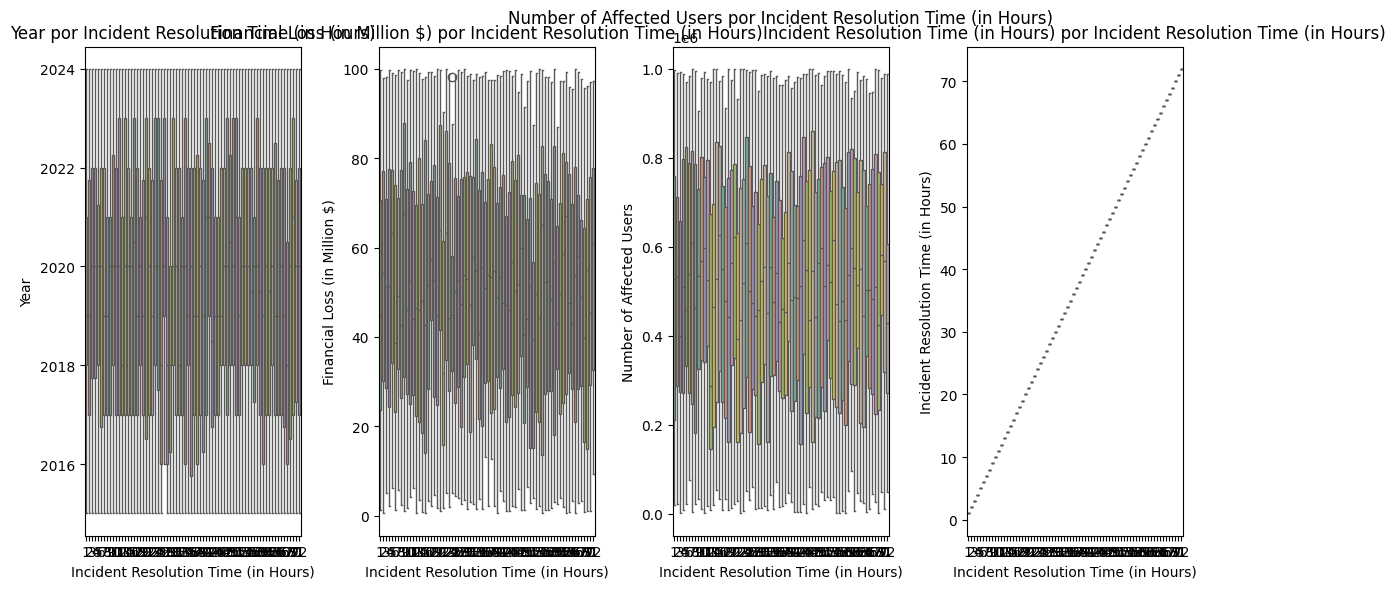

,Coluna,Q1 (25%),Q3 (75%),IQR,Outliers Encontrados,% Outliers
0,Year,2017.0000,2022.00,5.0000,0,0.0
1,Financial Loss (in Million $),25.7575,75.63,49.8725,0,0.0
2,Number of Affected Users,255805.2500,758088.50,502283.2500,0,0.0
3,Incident Resolution Time (in Hours),19.0000,55.00,36.0000,0,0.0



=== 4. MATRIZES DE CORRELAÇÃO (PEARSON & SPEARMAN - M) ===


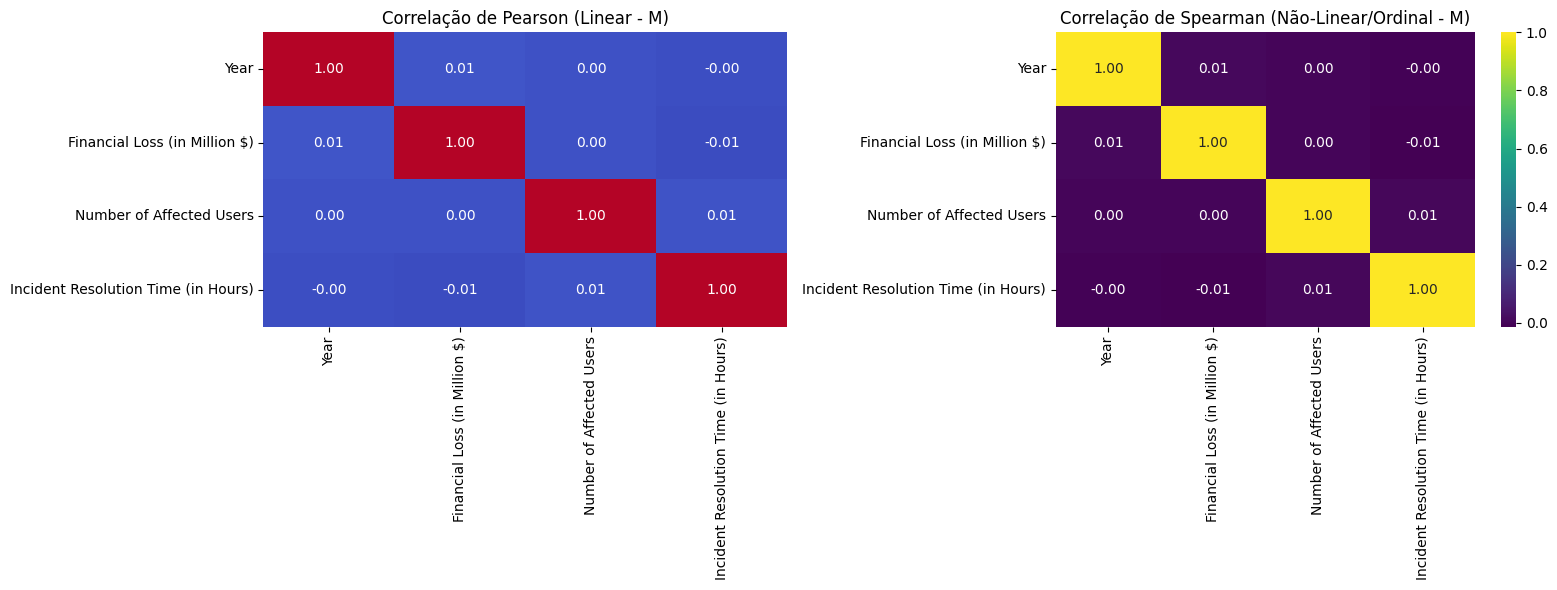

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from google.colab import files

# 1. Carregamento do Dataset
print("=== 1. CARREGAMENTO DOS DADOS ===")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

# Visão Geral
print(f"\nDimensão do Dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("\nPrimeiras 5 linhas:")
display(df.head())

print("\nInformação sobre Tipos de Dados e Nulos:")
print(df.info())

# 2. Análise Univariada: Estatística Descritiva, Skewness e Kurtosis (M)
print("\n=== 2. ANÁLISE UNIVARIADA & ESTATÍSTICA DESCRITIVA (M) ===")
num_cols = df.select_dtypes(include=[np.number]).columns

stats_summary = []
for col in num_cols:
    data_col = df[col].dropna()
    stats_summary.append({
        "Coluna": col,
        "Média": data_col.mean(),
        "Mediana": data_col.median(),
        "Desvio Padrão": data_col.std(),
        "Mínimo": data_col.min(),
        "Máximo": data_col.max(),
        "Skewness (Assimetria)": skew(data_col),
        "Kurtosis (Curtose)": kurtosis(data_col)
    })

df_stats = pd.DataFrame(stats_summary)
display(df_stats)

# Distribuição da Variável Alvo
target_col = 'Threat Level' if 'Threat Level' in df.columns else df.columns[-1]
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=target_col, palette='viridis')
plt.title(f'Distribuição da Variável Alvo: {target_col} (M)')
plt.ylabel('Contagem')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Histogramas e KDEs das Variáveis Numéricas
df[num_cols].hist(figsize=(12, 8), bins=30, edgecolor='black')
plt.suptitle('Histogramas das Variáveis Numéricas (M)', fontsize=14)
plt.tight_layout()
plt.show()

# 3. Análise Bivariada e Deteção de Outliers via IQR (M)
print("\n=== 3. ANÁLISE BIVARIADA & DETEÇÃO DE OUTLIERS (IQR - M) ===")

plt.figure(figsize=(12, 6))
for i, col in enumerate(num_cols[:4], 1):
    plt.subplot(1, 4, i)
    sns.boxplot(data=df, y=col, x=target_col, palette='Set2')
    plt.title(f'{col} por {target_col}')
plt.tight_layout()
plt.show()

# Cálculo numérico de Outliers por IQR
outlier_summary = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers_count = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]
    outlier_summary.append({
        "Coluna": col,
        "Q1 (25%)": q1,
        "Q3 (75%)": q3,
        "IQR": iqr,
        "Outliers Encontrados": outliers_count,
        "% Outliers": round((outliers_count / len(df)) * 100, 2)
    })

display(pd.DataFrame(outlier_summary))

# 4. Análise de Correlação: Pearson e Spearman (M)
print("\n=== 4. MATRIZES DE CORRELAÇÃO (PEARSON & SPEARMAN - M) ===")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pearson
corr_pearson = df[num_cols].corr(method='pearson')
sns.heatmap(corr_pearson, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[0], cbar=False)
axes[0].set_title('Correlação de Pearson (Linear - M)')

# Spearman
corr_spearman = df[num_cols].corr(method='spearman')
sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='viridis', ax=axes[1])
axes[1].set_title('Correlação de Spearman (Não-Linear/Ordinal - M)')

plt.tight_layout()
plt.show()